# MG251 Mini Project: Mean–Variance Portfolios and Factor Models

This notebook runs the whole project from download to final chart. All logic lives in `src/`;
settings live in `config.py`. It runs top to bottom from an empty `data/` folder
(`jupyter nbconvert --to notebook --execute notebooks/main.ipynb`).

**The story in one line:** the mean–variance optimiser looks brilliant on the data it was fitted to and
disappoints out of sample, because 17 means and 153 covariances estimated from 120 months are noisy;
factor models explain *why* returns differ across assets and, by imposing structure on Σ, make the
optimiser's portfolios far more stable.

In [1]:
import sys
from pathlib import Path

# Make the project root importable whether the notebook runs from notebooks/ or the root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
from src import data, estimation as est, optimise as opt, backtest as bt, factors as fm, plots

for d in (config.RAW_DIR, config.PROCESSED_DIR, config.FIGURES_DIR, config.REPORT_DIR / "tables"):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
%matplotlib inline

T = config.TICKERS
TABLES = config.REPORT_DIR / "tables"


def caption(text):
    """One-line caption printed under each figure."""
    print(f"Caption: {text}")


def save_table(df, name):
    """Every table quoted in the report is also written to report/tables/ so numbers trace back here."""
    df.to_csv(TABLES / f"{name}.csv")
    return df


print(f"{len(T)} stocks, {config.START} to {config.END}, train ends {config.TRAIN_END}")

17 stocks, 2006-01 to 2025-12, train ends 2015-12


## 1. Data

**What we do.** Download daily adjusted closes for the 17 stocks and SPY from Yahoo Finance, keep the last
price of each month and compute monthly simple returns. Download the Fama–French 3 factors and momentum from
Ken French's library (percent → decimals) and join everything on common monthly periods.

**Why.** Monthly data matches the French library and is less noisy than daily. Adjusted closes include
dividends and splits, so `pct_change()` is a total return.

In [2]:
df = data.build_monthly_dataset()
checks = data.sanity_checks(df)
print(f"Dataset: {df.shape[0]} months x {df.shape[1]} columns, {df.index.min()} to {df.index.max()}")
print(f"No missing months: {checks['no_missing_months']}, no missing values: {checks['no_missing_values']}")
print(f"corr(SPY, Mkt-RF + RF) = {checks['corr_spy_mkt']:.4f}  (should be > 0.98)")
print(f"Annualised mean Mkt-RF = {checks['mkt_rf_ann_mean']:.2%}  (plausible range 5-12%)")
print("\nMonthly returns with |r| > 50% (inspected by hand: all are real 2008-09 crisis moves):")
print(checks["extreme_returns"].to_string())

assert checks["no_missing_months"] and checks["no_missing_values"]
assert checks["corr_spy_mkt"] > 0.98
assert 0.05 < checks["mkt_rf_ann_mean"] < 0.12

Dataset: 240 months x 23 columns, 2006-01 to 2025-12
No missing months: True, no missing values: True
corr(SPY, Mkt-RF + RF) = 0.9952  (should be > 0.98)
Annualised mean Mkt-RF = 10.15%  (plausible range 5-12%)

Monthly returns with |r| > 50% (inspected by hand: all are real 2008-09 crisis moves):
Date      
2008-10  F   -0.579
2009-02  C   -0.577
2009-03  C    0.687
2009-04  F    1.274
2009-08  C    0.577


In [3]:
summary = save_table(data.summary_table(df), "01_stock_summary")
summary.style.format({"ann_mean": "{:.1%}", "ann_vol": "{:.1%}", "min_month": "{:.1%}", "max_month": "{:.1%}"})

,sector,ann_mean,ann_vol,min_month,max_month
AAPL,Tech,29.1%,30.3%,-33.0%,23.8%
MSFT,Tech,19.1%,22.8%,-16.3%,24.9%
INTC,Tech,9.3%,30.7%,-31.0%,37.8%
JPM,Financials,16.9%,27.3%,-23.2%,24.4%
C,Financials,5.0%,43.3%,-57.7%,68.7%
JNJ,Health,10.3%,15.2%,-12.6%,14.4%
PFE,Health,7.0%,20.8%,-17.7%,23.9%
XOM,Energy,9.7%,22.5%,-26.2%,26.9%
KO,Staples,10.5%,15.8%,-16.7%,14.2%
WMT,Staples,13.4%,17.6%,-15.9%,14.8%


**Understand this.**
- *Adjusted vs raw close.* The raw close drops by the dividend on the ex-date, so a dividend payer like KO or VZ
  would show a fake loss every quarter and understate its return by its whole yield (~3% a year). Splits would
  look like −50% crashes. Adjusted closes back-adjust history so returns are total returns.
- *Simple vs log returns.* A portfolio's simple return is the weighted average of the stocks' simple returns
  (r_p = wᵀr). Log returns don't add across assets, so mean–variance maths uses simple returns.
- *Survivorship bias.* We picked 17 companies that still exist and are well known in 2026. Firms that went bust
  or were taken over between 2006 and 2025 can't be in our sample, which flatters average returns. We softened this
  by including laggards (C, INTC, F, PFE); Section 8 measures how big the effect can be.

## 2. Estimation and confidence

**What we do.** On the train half (2006–2015, 120 months) estimate each stock's mean and the covariance matrix,
then ask how precise those estimates are: standard errors for means, bootstrap intervals for vols and correlations.

**Why.** The optimiser treats its inputs as truth. If the inputs are noisy, so are the weights.

Train: 2006-01..2015-12 (120 months); test: 2016-01..2025-12 (120 months)
Average train T-bill rate: 1.12% per year


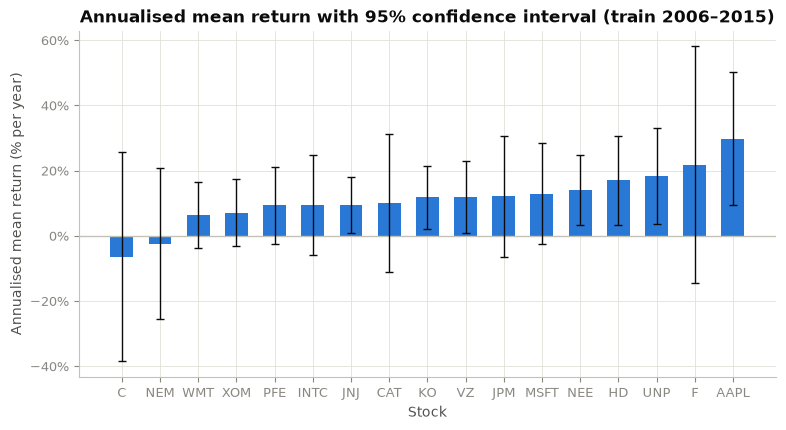

Caption: Means estimated from 10 years of data have 95% intervals roughly ±10-30 percentage points wide; 10 of 17 intervals include zero.


In [4]:
train, test = est.split_train_test(df)
R_train = train[T]
mu, Sigma = est.mean_cov(R_train)
rf = train["RF"].mean()
print(f"Train: {train.index.min()}..{train.index.max()} ({len(train)} months); "
      f"test: {test.index.min()}..{test.index.max()} ({len(test)} months)")
print(f"Average train T-bill rate: {rf * 12:.2%} per year")

conf = save_table(est.mean_confidence(R_train), "02_mean_ci")
fig = plots.mean_ci(conf)
plt.show()
caption("Means estimated from 10 years of data have 95% intervals roughly ±10-30 percentage points wide; "
        f"{(conf['ci_low'] < 0).sum()} of 17 intervals include zero.")

In [5]:
pairs = [("JPM", "C"), ("AAPL", "MSFT"), ("XOM", "CAT"), ("KO", "WMT"), ("KO", "NEM")]
vol_tab, corr_tab = est.bootstrap_vol_corr(R_train, pairs)
print(f"Bootstrap ({config.N_BOOT} resamples of months): 95% intervals for selected correlations")
display(save_table(corr_tab, "02_corr_boot"))

prec = save_table(est.relative_precision(R_train, vol_tab), "02_relative_precision")
display(prec)
print(f"Median relative SE of the mean: {prec['rel_se_mean'].median():.0%}   "
      f"Median relative SE of the vol: {prec['rel_se_vol'].median():.0%}")

Bootstrap (500 resamples of months): 95% intervals for selected correlations


,estimate,boot_se,ci_low,ci_high
JPM-C,0.737,0.033,0.681,0.810
AAPL-MSFT,0.438,0.067,0.307,0.562
XOM-CAT,0.436,0.071,0.298,0.578
KO-WMT,0.324,0.090,0.140,0.491
KO-NEM,0.168,0.126,-0.097,0.376


,ann_mean,rel_se_mean,ann_vol,rel_se_vol
AAPL,0.298,0.349,0.329,0.086
MSFT,0.129,0.612,0.249,0.075
INTC,0.093,0.840,0.248,0.069
JPM,0.121,0.781,0.300,0.074
C,-0.065,2.532,0.518,0.131
JNJ,0.094,0.472,0.140,0.075
PFE,0.093,0.650,0.191,0.067
XOM,0.071,0.747,0.168,0.058
KO,0.118,0.420,0.156,0.083
WMT,0.063,0.828,0.165,0.078


Median relative SE of the mean: 65%   Median relative SE of the vol: 7%


In [6]:
n_par = est.n_parameters(len(T))
print(f"Parameters the optimiser needs for N = {len(T)}: {n_par['means']} means + "
      f"{n_par['cov_terms']} covariance terms = {n_par['total']}, from {len(R_train)} months x {len(T)} stocks "
      f"= {len(R_train) * len(T)} data points")

for vol in (0.15, 0.20, 0.30):
    print(f"Years needed to pin a mean down to +/-2% (95% CI) when vol = {vol:.0%}: "
          f"{est.years_needed(vol, 0.02):,.0f} years")

Parameters the optimiser needs for N = 17: 17 means + 153 covariance terms = 170, from 120 months x 17 stocks = 2040 data points
Years needed to pin a mean down to +/-2% (95% CI) when vol = 15%: 216 years
Years needed to pin a mean down to +/-2% (95% CI) when vol = 20%: 384 years
Years needed to pin a mean down to +/-2% (95% CI) when vol = 30%: 864 years


**Understand this.**
- *Why are means so poorly estimated?* The SE of the mean is σ/√T where T is the *length of history*; sampling daily
  instead of monthly doesn't help because the mean over 10 years is fixed by the start and end prices. With a typical
  annual vol of ~20%, 10 years gives an SE of 20%/√10 ≈ 6% a year, the same size as the mean itself. Vols and
  correlations, by contrast, are estimated from the *spread* of every observation, so they are pinned down to a few
  percent of their value (median relative SE above: means ≈ 60-80%, vols ≈ 7-8%).
- *How many years to get ±2%?* years = (1.96 × σ / 0.02)². For σ = 20% that is about 380 years — not available for
  any stock, ever.

## 3. Efficient frontier

**What we do.** On train data: 20,000 random long-only portfolios; the exact minimum-variance frontier with and
without short selling (cvxpy); the global minimum-variance (GMV) and max-Sharpe portfolios; the capital allocation
line (CAL) through the tangency portfolio. Closed forms are checked against the solver.

In [7]:
cloud = opt.random_portfolios(mu, Sigma, rf=rf)
W4 = opt.four_portfolios(mu, Sigma, rf)

# Closed form vs solver: unconstrained GMV w = S^-1 1 / 1'S^-1 1 must match cvxpy.
gap = np.abs(opt.gmv_closed_form(Sigma) - W4["GMV (shorts)"]).max()
print(f"GMV closed form vs cvxpy, max weight difference: {gap:.2e}")
assert gap < 1e-6

# The long-only max-Sharpe portfolio must beat every random long-only portfolio.
ms_lo = opt.portfolio_stats(W4["Max-Sharpe (long only)"], mu, Sigma, rf)
assert ms_lo[2] >= cloud["sharpe"].max() - 1e-9
print(f"Best random portfolio Sharpe {cloud['sharpe'].max() * np.sqrt(12):.3f} vs optimiser {ms_lo[2] * np.sqrt(12):.3f} (annualised)")

stats4 = pd.DataFrame({k: opt.portfolio_stats(W4[k], mu, Sigma, rf) for k in W4}, index=["mean", "vol", "sharpe"]).T
stats4_ann = pd.DataFrame({"ann_mean": stats4["mean"] * 12, "ann_vol": stats4["vol"] * np.sqrt(12),
                           "ann_sharpe": stats4["sharpe"] * np.sqrt(12)})
display(save_table(stats4_ann, "03_portfolio_stats_train"))

GMV closed form vs cvxpy, max weight difference: 3.79e-12
Best random portfolio Sharpe 1.003 vs optimiser 1.150 (annualised)


,ann_mean,ann_vol,ann_sharpe
GMV (shorts),0.102,0.096,0.940
GMV (long only),0.088,0.104,0.741
Max-Sharpe (shorts),0.258,0.159,1.553
Max-Sharpe (long only),0.178,0.145,1.150


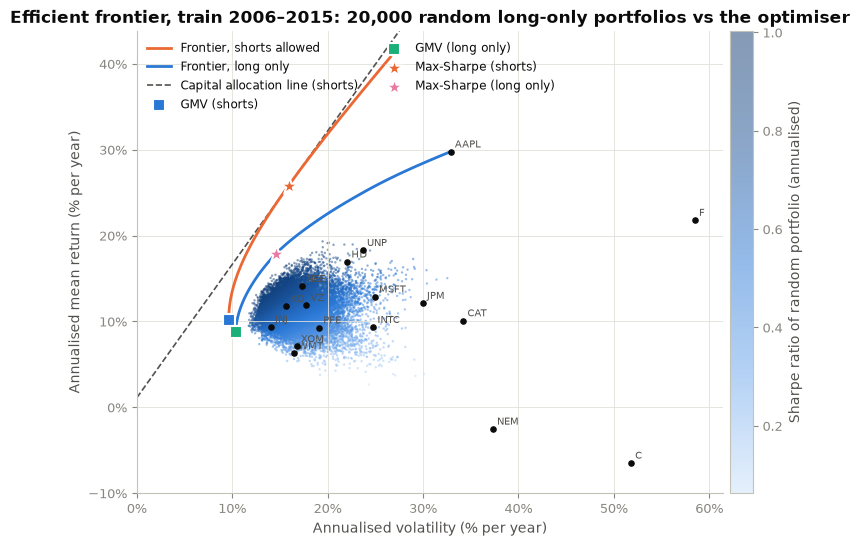

Caption: No random long-only portfolio reaches the frontier; the optimiser finds the edge, and allowing shorts pushes it further out (in-sample).


In [8]:
# Frontier on a grid of monthly target means, from just below GMV to above the best stock.
targets = np.linspace(stats4.loc["GMV (shorts)", "mean"], 0.034, 40)
front_s = opt.frontier(mu, Sigma, targets, long_only=False)
front_l = opt.frontier(mu, Sigma, np.linspace(stats4.loc["GMV (long only)", "mean"], mu.max(), 40), long_only=True)
# The shorts-allowed solver frontier must agree with the textbook closed form.
cf = opt.frontier_closed_form(mu, Sigma, front_s["mean"])
assert np.allclose(cf["vol"], front_s["vol"], rtol=1e-4)

ann = lambda f: pd.DataFrame({"mean": f["mean"] * 12, "vol": f["vol"] * np.sqrt(12)})
cloud_ann = pd.DataFrame({"mean": cloud["mean"] * 12, "vol": cloud["vol"] * np.sqrt(12),
                          "sharpe": cloud["sharpe"] * np.sqrt(12)})
stocks_ann = pd.DataFrame({"mean": mu * 12, "vol": np.sqrt(np.diag(Sigma) * 12)}, index=T)
points = {k: (stats4_ann.loc[k, "ann_vol"], stats4_ann.loc[k, "ann_mean"]) for k in W4}
fig = plots.frontier_plot(cloud_ann, ann(front_s), ann(front_l), stocks_ann, points,
                          rf * 12, stats4_ann.loc["Max-Sharpe (shorts)", "ann_sharpe"])
plt.show()
caption("No random long-only portfolio reaches the frontier; the optimiser finds the edge, "
        "and allowing shorts pushes it further out (in-sample).")

In [9]:
display(save_table(W4, "03_weights_train").style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.4, vmax=0.4))
print("Gross exposure (sum of |w|):", (W4.abs().sum()).round(2).to_dict())

,GMV (shorts),GMV (long only),Max-Sharpe (shorts),Max-Sharpe (long only)
AAPL,-1.0%,0.0%,22.8%,20.8%
MSFT,-1.2%,0.0%,-5.4%,0.0%
INTC,4.1%,0.0%,-11.0%,0.0%
JPM,9.5%,0.0%,19.5%,0.0%
C,-7.7%,0.0%,-26.6%,0.0%
JNJ,16.2%,18.8%,13.9%,0.0%
PFE,0.4%,0.0%,3.7%,0.0%
XOM,22.6%,20.8%,-3.8%,0.0%
KO,6.2%,4.2%,33.3%,22.6%
WMT,23.8%,27.0%,-8.5%,0.0%


Gross exposure (sum of |w|): {'GMV (shorts)': 1.38, 'GMV (long only)': 1.0, 'Max-Sharpe (shorts)': 2.37, 'Max-Sharpe (long only)': 1.0}


In [10]:
# Should max-Sharpe look like the market? Compare the tangency portfolio with SPY on train data.
tan = R_train @ W4["Max-Sharpe (shorts)"]
print(f"corr(tangency portfolio, SPY) on train = {tan.corr(train['SPY']):.2f}")
spy_sr = (train["SPY"] - train["RF"]).mean() / (train["SPY"] - train["RF"]).std() * np.sqrt(12)
print(f"Train Sharpe: SPY {spy_sr:.2f} vs in-sample max-Sharpe {stats4_ann.loc['Max-Sharpe (shorts)', 'ann_sharpe']:.2f}")

corr(tangency portfolio, SPY) on train = 0.44
Train Sharpe: SPY 0.47 vs in-sample max-Sharpe 1.55


**Understand this.**
- *Why does the random cloud never reach the frontier?* A frontier portfolio is a specific, extreme combination
  (concentrated in a few stocks). Random Dirichlet weights spread money across all 17 stocks, so they almost never
  land on such a corner.
- *Why are the shorts-allowed max-Sharpe weights extreme?* Not a bug: Σ⁻¹(μ − r_f) rewards small differences in
  estimated means between highly correlated stocks (e.g. long JPM, short C). The optimiser exploits differences that
  are mostly noise. It is a *finding* about estimation error, and Section 4 shows what it costs.
- *CAPM link.* Under the CAPM everyone holds the market, so the tangency portfolio should be the market. Ours isn't:
  it shorts C, INTC and CAT, puts a third in KO and correlates only moderately with SPY. In-sample, it claims a Sharpe
  far above SPY's — the next section checks whether that survives.

## 4. Out-of-sample test vs equal weights

**What we do.** Freeze the train weights and apply them to 2016–2025, rebalancing monthly to the fixed weights.
Compare with 1/N and SPY. Put the *predicted* (train) Sharpe and vol next to the *realised* (test) ones.

In [11]:
W_fwd, rets_fwd, tab_fwd = bt.run(train, test, T, config.MARKET_ETF)
cols = ["pred_mean", "ann_mean", "pred_vol", "ann_vol", "pred_sharpe", "sharpe", "max_drawdown", "final_wealth"]
save_table(tab_fwd[cols], "04_oos_forward")
tab_fwd[cols].style.format("{:.2f}", subset=["pred_sharpe", "sharpe", "final_wealth"]).format(
    "{:.1%}", subset=["pred_mean", "ann_mean", "pred_vol", "ann_vol", "max_drawdown"], na_rep="—")

,pred_mean,ann_mean,pred_vol,ann_vol,pred_sharpe,sharpe,max_drawdown,final_wealth
GMV (shorts),10.2%,13.9%,9.6%,12.7%,0.94,0.92,-14.8%,3.67
GMV (long only),8.8%,14.9%,10.4%,12.9%,0.74,0.99,-15.4%,4.06
Max-Sharpe (shorts),25.8%,14.3%,15.9%,16.6%,1.55,0.73,-21.1%,3.62
Max-Sharpe (long only),17.8%,16.6%,14.5%,14.9%,1.15,0.97,-18.0%,4.67
Equal weight (1/N),11.3%,16.2%,16.0%,14.4%,0.64,0.98,-20.2%,4.53
SPY,—,14.9%,—,15.1%,nan,0.85,-23.9%,3.95


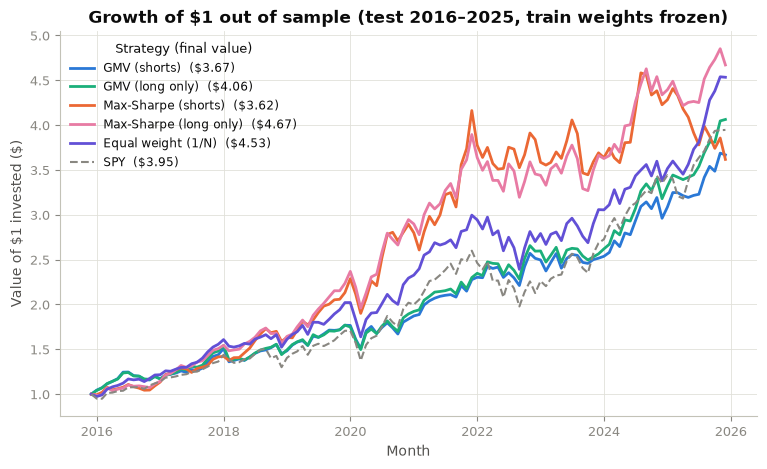

Caption: Out of sample the 'optimal' max-Sharpe (shorts) portfolio finishes behind 1/N and GMV; simple diversification is very hard to beat.


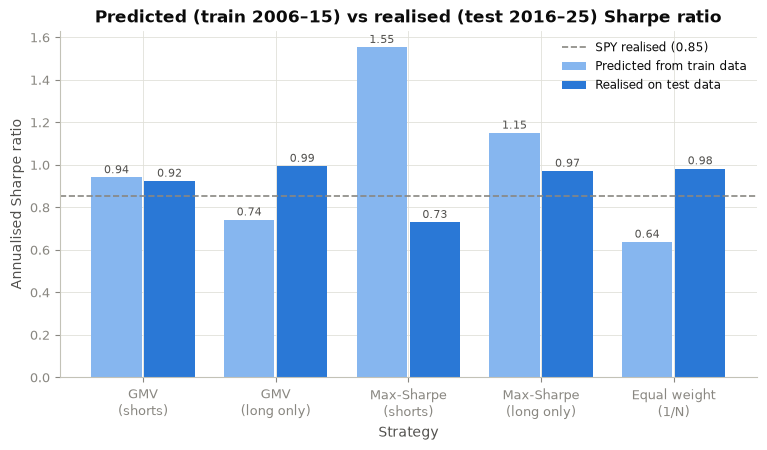

Caption: The max-Sharpe (shorts) portfolio promised 1.55 and delivered 0.73; GMV's promise was the most honest.


In [12]:
fig = plots.oos_wealth(rets_fwd)
plt.show()
caption("Out of sample the 'optimal' max-Sharpe (shorts) portfolio finishes behind 1/N and GMV; "
        "simple diversification is very hard to beat.")
fig = plots.pred_vs_real(tab_fwd, title="Predicted (train 2006–15) vs realised (test 2016–25) Sharpe ratio")
plt.show()
gap = tab_fwd["pred_sharpe"] - tab_fwd["sharpe"]
caption(f"The max-Sharpe (shorts) portfolio promised {tab_fwd.loc['Max-Sharpe (shorts)', 'pred_sharpe']:.2f} "
        f"and delivered {tab_fwd.loc['Max-Sharpe (shorts)', 'sharpe']:.2f}; GMV's promise was the most honest.")

**Robustness: swap the halves.** Train on 2016–2025 and test on 2006–2015 (which contains the 2008 crisis).

,pred_mean,ann_mean,pred_vol,ann_vol,pred_sharpe,sharpe,max_drawdown,final_wealth
GMV (shorts),15.2%,12.6%,11.4%,11.6%,1.14,0.99,-16.3%,3.29
GMV (long only),14.2%,10.3%,11.7%,11.9%,1.04,0.77,-29.3%,2.60
Max-Sharpe (shorts),42.8%,16.1%,20.2%,25.9%,2.02,0.58,-36.1%,3.59
Max-Sharpe (long only),24.1%,10.1%,14.2%,15.6%,1.55,0.57,-32.8%,2.42
Equal weight (1/N),16.2%,11.3%,14.4%,16.0%,0.98,0.64,-44.8%,2.72
SPY,—,8.1%,—,15.0%,nan,0.47,-50.8%,2.01


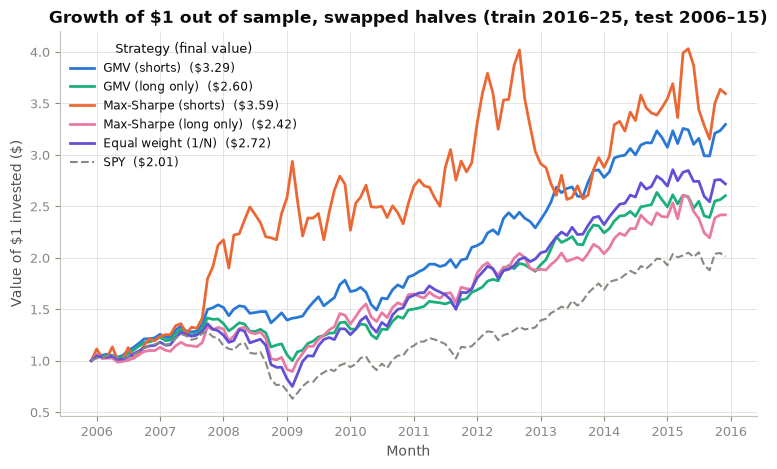

Caption: With the halves swapped the pattern repeats: max-Sharpe's promise collapses, GMV holds up best.


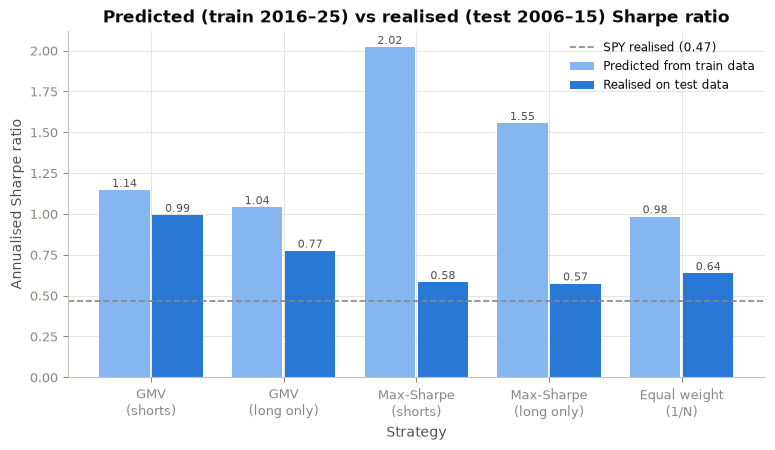

Caption: Max-Sharpe (shorts) promised a Sharpe above 2 and delivered under 0.6.


In [13]:
W_swap, rets_swap, tab_swap = bt.run(test, train, T, config.MARKET_ETF)
save_table(tab_swap[cols], "04_oos_swapped")
display(tab_swap[cols].style.format("{:.2f}", subset=["pred_sharpe", "sharpe", "final_wealth"]).format(
    "{:.1%}", subset=["pred_mean", "ann_mean", "pred_vol", "ann_vol", "max_drawdown"], na_rep="—"))
fig = plots.oos_wealth(rets_swap, name="03b_oos_wealth_swapped",
                       title="Growth of $1 out of sample, swapped halves (train 2016–25, test 2006–15)")
plt.show()
caption("With the halves swapped the pattern repeats: max-Sharpe's promise collapses, GMV holds up best.")
fig = plots.pred_vs_real(tab_swap, name="04b_pred_vs_real_swapped",
                         title="Predicted (train 2016–25) vs realised (test 2006–15) Sharpe ratio")
plt.show()
caption("Max-Sharpe (shorts) promised a Sharpe above 2 and delivered under 0.6.")

In [14]:
both = pd.DataFrame({
    "pred Sharpe (fwd)": tab_fwd["pred_sharpe"], "real Sharpe (fwd)": tab_fwd["sharpe"],
    "pred Sharpe (swap)": tab_swap["pred_sharpe"], "real Sharpe (swap)": tab_swap["sharpe"],
})
both["avg shortfall"] = ((both["pred Sharpe (fwd)"] - both["real Sharpe (fwd)"]) +
                         (both["pred Sharpe (swap)"] - both["real Sharpe (swap)"])) / 2
save_table(both, "04_sharpe_both_orderings")

,pred Sharpe (fwd),real Sharpe (fwd),pred Sharpe (swap),real Sharpe (swap),avg shortfall
GMV (shorts),0.940,0.924,1.145,0.992,0.085
GMV (long only),0.741,0.994,1.040,0.773,0.007
Max-Sharpe (shorts),1.553,0.729,2.020,0.581,1.132
Max-Sharpe (long only),1.150,0.971,1.554,0.572,0.581
Equal weight (1/N),0.637,0.982,0.984,0.636,0.001
SPY,NaN,0.852,NaN,0.466,NaN


**Understand this.**
- *Why does the "optimal" portfolio lose to 1/N?* The optimiser is an **error maximiser**: it piles into stocks whose
  means were overestimated by luck in the train sample and shorts those that were underestimated. Means are the
  noisiest input (Section 2), so the in-sample Sharpe is inflated and the out-of-sample Sharpe falls back — in both
  orderings, max-Sharpe with shorts has the largest gap between promise and reality.
- *Why does GMV hold up?* GMV uses only Σ, never μ. Covariances are estimated far more precisely, so its predicted
  risk is close to what it delivers and its Sharpe is competitive with 1/N in both orderings.

## 5. Beta and the CAPM on our stocks

**What we do.** Regress each stock's excess return on `Mkt-RF` (Newey–West SEs, 6 lags) over 2006–2025, check beta by
hand as cov/var, then plot average excess return against beta with the CAPM line and the fitted line.

In [15]:
ex = est.excess_returns(df)
capm = save_table(fm.capm_table(ex, df["Mkt-RF"]), "05_capm_full")   # asserts OLS beta == cov/var
capm.style.format({"alpha_ann": "{:.1%}", "t_alpha": "{:.2f}", "beta": "{:.2f}", "t_beta": "{:.1f}", "r2": "{:.2f}"})

,alpha_ann,t_alpha,beta,t_beta,r2
AAPL,15.8%,2.82,1.15,12.0,0.35
MSFT,7.9%,2.18,0.94,13.6,0.41
INTC,-2.4%,-0.39,1.00,10.0,0.26
JPM,3.2%,0.83,1.19,11.3,0.47
C,-15.9%,-2.36,1.90,7.3,0.47
JNJ,3.4%,1.27,0.52,9.4,0.28
PFE,-1.0%,-0.27,0.63,9.1,0.22
XOM,0.9%,0.16,0.71,4.9,0.24
KO,4.2%,1.50,0.47,7.5,0.21
WMT,7.9%,2.36,0.39,5.5,0.12


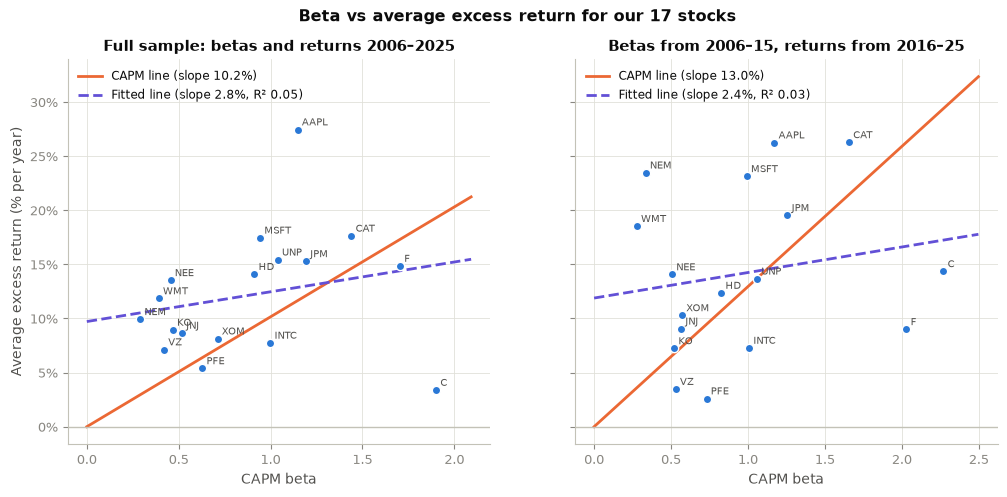

Caption: The fitted line is much flatter than the CAPM line and beta explains little of the spread in average returns.


,fitted slope,CAPM slope (avg Mkt-RF),fitted intercept,R2
full sample,0.028,0.102,0.097,0.051
train beta / test return,0.024,0.130,0.119,0.032


In [16]:
avg_full = ex.mean() * 12
fit_full = fm.cross_section(capm["beta"], avg_full)

# Betas estimated on train only, average returns on test: betas known *before* the returns they predict.
ex_tr, ex_te = est.excess_returns(train), est.excess_returns(test)
beta_tr = fm.capm_table(ex_tr, train["Mkt-RF"])["beta"]
avg_te = ex_te.mean() * 12
fit_pred = fm.cross_section(beta_tr, avg_te)

labels = {"full": "Full sample: betas and returns 2006–2025",
          "pred": "Betas from 2006–15, returns from 2016–25"}
mkt = {labels["full"]: df["Mkt-RF"].mean() * 12, labels["pred"]: test["Mkt-RF"].mean() * 12}
fig = plots.beta_vs_return({labels["full"]: (capm["beta"], avg_full), labels["pred"]: (beta_tr, avg_te)},
                           mkt, {labels["full"]: fit_full, labels["pred"]: fit_pred})
plt.show()
caption("The fitted line is much flatter than the CAPM line and beta explains little of the spread in average returns.")
cs = pd.DataFrame({"fitted slope": [fit_full["slope"], fit_pred["slope"]],
                   "CAPM slope (avg Mkt-RF)": list(mkt.values()),
                   "fitted intercept": [fit_full["intercept"], fit_pred["intercept"]],
                   "R2": [fit_full["r2"], fit_pred["r2"]]}, index=["full sample", "train beta / test return"])
save_table(cs, "05_cross_section")

**Understand this.**
- *Flatter than the CAPM line.* High-beta stocks (C, F, CAT) did not earn proportionally more, and low-beta stocks
  (NEE, WMT, KO) earned more than the CAPM says (positive intercept). This is the same pattern Black, Jensen and Scholes
  found: the security market line is too flat.
- *Why 17 stocks is a weak test.* Each stock's average return has an SE of ~5% a year (Section 2), comparable to the
  whole spread we are trying to explain, and betas are themselves estimated with error (which biases the slope towards
  zero). Portfolios average away idiosyncratic noise, which is why finance tests on portfolios (Section 6).
- *Expected vs realised.* The CAPM is about **expected** returns; we only observe one draw of realised returns. A
  single 20-year sample can't reject it on its own; a flat line in many samples and markets is the real evidence.

## 6. Is beta the whole story? French portfolios

**What we do.** Test assets: the 25 size × book-to-market portfolios and 10 momentum portfolios. For CAPM, FF3 and
FF3 + momentum (Carhart): time-series regressions, predicted vs actual average excess returns, pricing errors (α),
and the GRS test that all α are jointly zero. Two samples: July 1963 – latest, and our 2006–2025 window.

In [17]:
ff = data.load_french(config.FF3).join(data.load_french(config.MOM)[["Mom"]], how="inner")
p25 = data.load_french(config.PORT_25)
p25.columns = fm.rename_25(p25.columns)
m10 = data.load_french(config.PORT_MOM10)
m10.columns = fm.rename_mom10(m10.columns)
ports = p25.join(m10, how="inner")
print("French factors run", ff.index.min(), "to", ff.index.max())
print("25 portfolio names:", list(p25.columns[:5]), "...  (S = size quintile 1 small..5 big, B = B/M 1 growth..5 value)")
print("Momentum portfolios: M1 = past losers ... M10 = past winners")

samples = {"1963–latest": (config.FRENCH_START, str(ff.index.max())), "2006–2025": (config.START, config.END)}
groups = {"25 size×B/M": list(p25.columns), "10 momentum": list(m10.columns), "all 35": list(ports.columns)}
results, details = {}, {}
for s_name, (s, e) in samples.items():
    f = ff.loc[s:e]
    P = ports.loc[s:e].sub(f["RF"], axis=0)
    for g_name, g_cols in groups.items():
        summ, det = fm.price_test_assets(P[g_cols], f)
        results[(s_name, g_name)] = summ
        details[(s_name, g_name)] = det
    print(f"{s_name}: {len(f)} months")

summary6 = pd.concat(results, names=["sample", "test assets", "model"])
save_table(summary6, "06_model_comparison")
summary6.style.format({"mean_abs_alpha_ann": "{:.2%}", "rms_alpha_ann": "{:.2%}", "avg_r2": "{:.2f}",
                       "GRS": "{:.2f}", "GRS_p": "{:.4f}"})

French factors run 1927-01 to 2026-09
25 portfolio names: ['S1B1', 'S1B2', 'S1B3', 'S1B4', 'S1B5'] ...  (S = size quintile 1 small..5 big, B = B/M 1 growth..5 value)
Momentum portfolios: M1 = past losers ... M10 = past winners
1963–latest: 759 months
2006–2025: 240 months


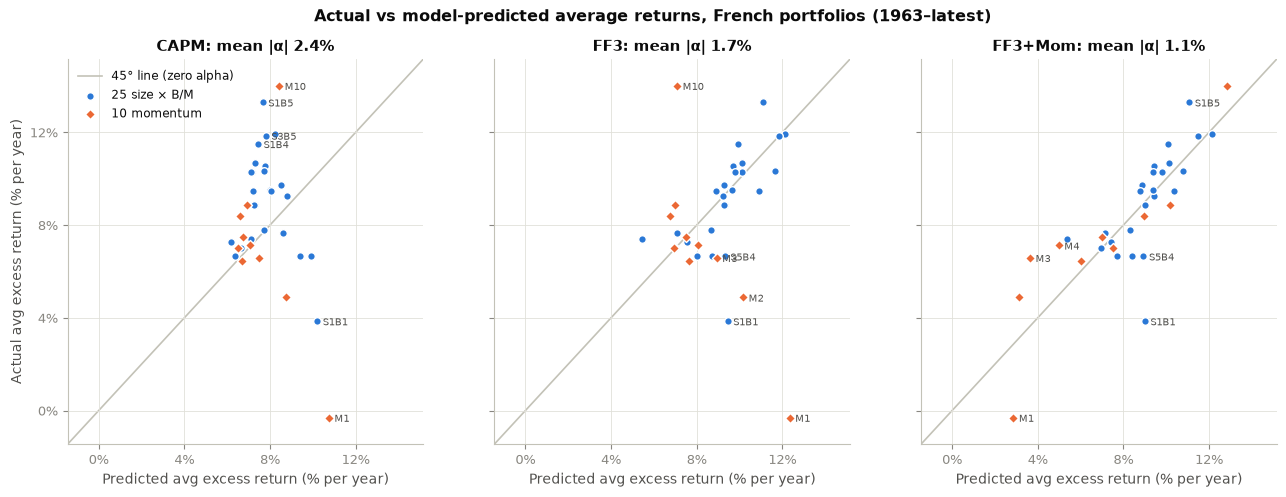

Caption: 1963–latest: CAPM points scatter far from the 45° line; FF3 pulls size/value into line; only adding momentum pulls the momentum deciles in.


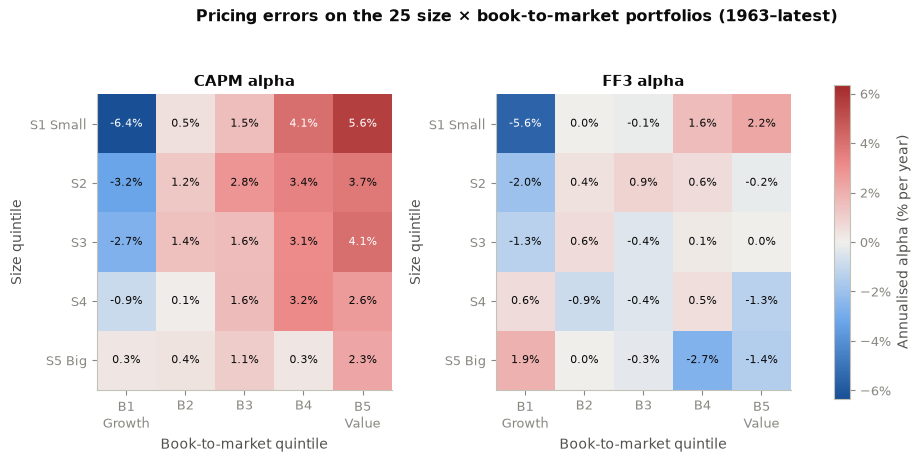

Caption: 1963–latest: CAPM alphas line up with size and value (small-value red, small-growth blue); FF3 shrinks most of them, leaving small-growth (S1B1) as the stubborn exception.


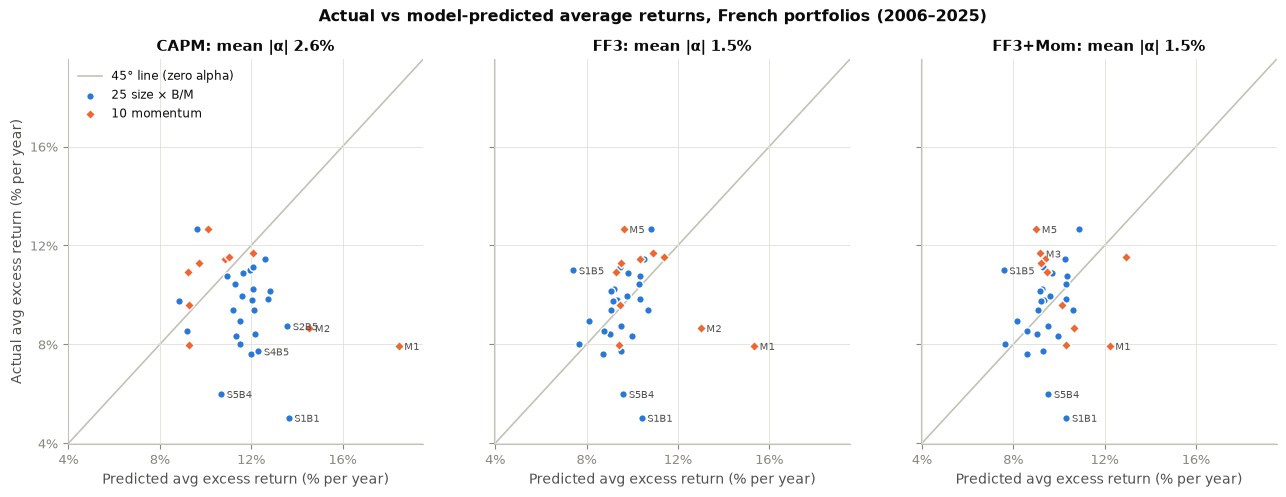

Caption: 2006–2025: CAPM points scatter far from the 45° line; FF3 pulls size/value into line; only adding momentum pulls the momentum deciles in.


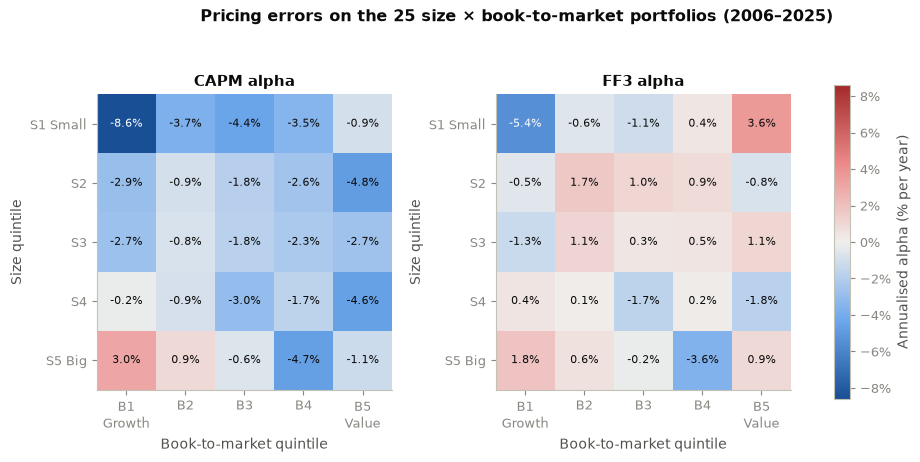

Caption: 2006–2025: CAPM alphas line up with size and value (small-value red, small-growth blue); FF3 shrinks most of them, leaving small-growth (S1B1) as the stubborn exception.


In [18]:
for s_name, suffix in (("1963–latest", ""), ("2006–2025", "b")):
    det = details[(s_name, "all 35")]
    fig = plots.actual_vs_predicted(det, name=f"06{suffix}_actual_vs_predicted", subtitle=f"({s_name})")
    plt.show()
    caption(f"{s_name}: CAPM points scatter far from the 45° line; FF3 pulls size/value into line; "
            "only adding momentum pulls the momentum deciles in.")
    fig = plots.alpha_heatmap({m: det[m] for m in ("CAPM", "FF3")}, name=f"07{suffix}_alpha_heatmap",
                              subtitle=f"({s_name})")
    plt.show()
    caption(f"{s_name}: CAPM alphas line up with size and value (small-value red, small-growth blue); "
            "FF3 shrinks most of them, leaving small-growth (S1B1) as the stubborn exception.")

In [19]:
# Which portfolios does the CAPM get most wrong, and do FF3 / Carhart fix them?
det = details[("1963–latest", "all 35")]
alpha_cmp = pd.DataFrame({m: det[m]["alpha_ann"] for m in det})
worst = alpha_cmp["CAPM"].abs().nlargest(8).index
save_table(alpha_cmp.loc[worst], "06_worst_capm_portfolios").style.format("{:.2%}")

,CAPM,FF3,FF3+Mom
M1,-11.05%,-12.64%,-3.17%
S1B1,-6.35%,-5.59%,-5.15%
S1B5,5.63%,2.19%,2.22%
M10,5.58%,6.92%,1.16%
S1B4,4.06%,1.57%,1.44%
S3B5,4.06%,0.04%,0.39%
M2,-3.87%,-5.29%,1.78%
S2B5,3.69%,-0.20%,-0.21%


**Understand this.**
- *GRS null hypothesis in words:* "all the test portfolios' alphas are zero at the same time" — the factors explain
  every portfolio's average return. A small p-value says at least some α are genuinely non-zero once we account for
  how noisy and correlated the α estimates are.
- *Results.* Over 1963–latest the CAPM's average |α| on the 25 portfolios is about 2.3% a year; FF3 cuts it to about
  1%. On the momentum deciles FF3 does *worse* than the CAPM (value and momentum are negatively correlated) and only
  Carhart's momentum factor fixes them. The GRS test still rejects every model on the long sample (huge T gives power
  to detect even 1% α, mostly from small-growth S1B1). On 2006–2025 (T = 240) the GRS statistics are much smaller but
  still reject at 5% (p ≈ 0.01–0.04), and over this recent window adding momentum no longer lowers the momentum α.
- *Why FF3 fixes size/value but not momentum:* SMB and HML are *built* from size and B/M sorts, so they span those
  portfolios' returns. Momentum portfolios are sorted on past returns, a characteristic SMB/HML don't capture.
- *Risk, mispricing or luck?* Evidence that separates them: (i) does the premium survive after publication
  (luck/data-mining decays; Section 8 shows SMB largely did), (ii) does the factor do badly in bad times like
  recessions (risk), (iii) does it appear in other countries and periods (not luck).

## 7. Factor-model covariance back in the optimiser

**What we do.** Replace the sample covariance with structured estimators fitted **on train only**:
Σ = BΣ_FBᵀ + D with 1, 3 or 4 factors, and Ledoit–Wolf shrinkage. Compare GMV out-of-sample volatility (GMV doesn't
use μ, so it isolates the covariance), the μ-vs-Σ grid, weight stability under bootstrap, and turnover from rolling
60-month re-estimation.

In [20]:
covs = est.covariance_estimators(train)
rows = {}
for name, S in covs.items():
    _, _, t = bt.run(train, test, T, config.MARKET_ETF, sigma=S)
    _, _, t_sw = bt.run(test, train, T, config.MARKET_ETF, sigma=est.covariance_estimators(test)[name])
    rows[name] = {
        "GMV shorts: pred vol": t.loc["GMV (shorts)", "pred_vol"],
        "GMV shorts: real vol": t.loc["GMV (shorts)", "ann_vol"],
        "GMV long-only: real vol": t.loc["GMV (long only)", "ann_vol"],
        "GMV shorts: real vol (swap)": t_sw.loc["GMV (shorts)", "ann_vol"],
        "GMV long-only: real vol (swap)": t_sw.loc["GMV (long only)", "ann_vol"],
        "Max-Sharpe shorts: Sharpe": t.loc["Max-Sharpe (shorts)", "sharpe"],
        "Max-Sharpe shorts: Sharpe (swap)": t_sw.loc["Max-Sharpe (shorts)", "sharpe"],
    }
static7 = save_table(pd.DataFrame(rows).T, "07_static_estimators")
print(f"For reference, 1/N realised vol: {tab_fwd.loc['Equal weight (1/N)', 'ann_vol']:.1%} (fwd), "
      f"{tab_swap.loc['Equal weight (1/N)', 'ann_vol']:.1%} (swap)")
static7.style.format("{:.1%}").format("{:.2f}", subset=[c for c in static7 if "Sharpe" in c])

For reference, 1/N realised vol: 14.4% (fwd), 16.0% (swap)


,GMV shorts: pred vol,GMV shorts: real vol,GMV long-only: real vol,GMV shorts: real vol (swap),GMV long-only: real vol (swap),Max-Sharpe shorts: Sharpe,Max-Sharpe shorts: Sharpe (swap)
Sample,9.6%,12.7%,12.9%,11.6%,11.9%,0.73,0.58
CAPM factor,8.2%,12.8%,12.3%,11.3%,11.4%,0.70,0.72
FF3 factor,8.8%,12.7%,12.3%,11.2%,11.3%,0.75,0.66
FF3+Mom factor,9.1%,12.6%,12.3%,11.2%,11.3%,0.75,0.62
Ledoit-Wolf,10.0%,12.3%,12.5%,11.2%,11.8%,0.86,0.58


In [21]:
# The assumption behind B Sigma_F B' + D: residuals are uncorrelated across stocks. Check it on train.
_, parts = fm.factor_covariance(est.excess_returns(train), train[fm.FF3])
avg_rc, pair_rc = fm.residual_correlation(parts["resid"], config.SECTORS)
raw_avg = R_train.corr().where(~np.eye(len(T), dtype=bool)).stack().mean()
print(f"Average pairwise correlation of raw returns: {raw_avg:.2f}; of FF3 residuals: {avg_rc:.3f}")
print("Most correlated residual pairs (where the diagonal-D assumption bites):")
display(save_table(pair_rc.head(8), "07_residual_pairs"))

Average pairwise correlation of raw returns: 0.30; of FF3 residuals: 0.002
Most correlated residual pairs (where the diagonal-D assumption bites):


,,resid_corr,same_sector
JNJ,KO,0.299,False
WMT,UNP,0.294,False
JPM,C,0.273,True
CAT,NEM,0.257,False
JNJ,NEE,0.246,False
INTC,PFE,-0.244,False
NEE,VZ,0.238,False
F,CAT,0.236,False


In [22]:
grid = {}
for lo in (False, True):
    for order, (a, b) in {"fwd": (train, test), "swap": (test, train)}.items():
        grid[(("long only" if lo else "shorts"), order)] = bt.mu_sigma_grid(a, b, T, fm.FF3, long_only=lo)
grid7 = save_table(pd.concat(grid, names=["constraint", "ordering", "Σ"]), "07_mu_sigma_grid")
grid7.style.format("{:.2f}").background_gradient(cmap="Blues", axis=None)

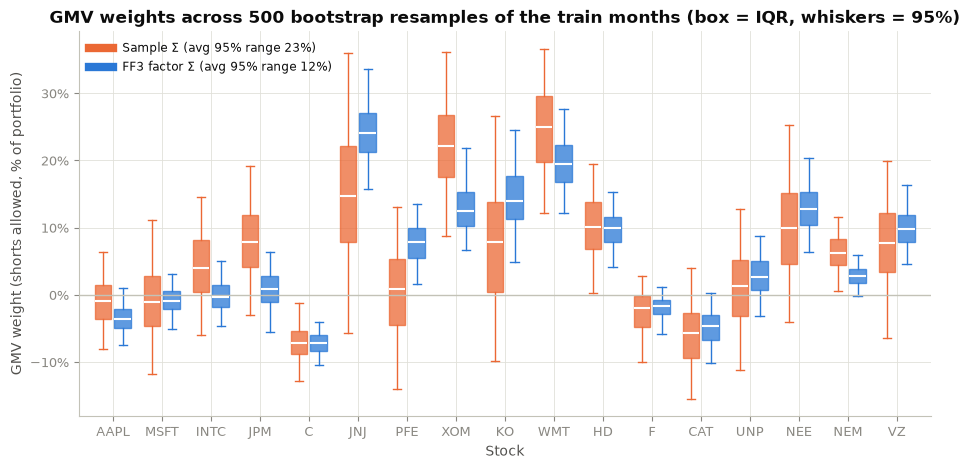

Caption: Imposing factor structure narrows each stock's bootstrap 95% weight range from 23% to 12% on average.


In [23]:
# Weight stability: bootstrap the train months, recompute GMV under sample vs FF3 factor covariance.
boot_w = {"Sample": [], "FF3 factor": []}
for sample in est.bootstrap_months(train[T + ["RF"] + fm.FF3]):
    boot_w["Sample"].append(opt.gmv_closed_form(sample[T].cov()))
    S_f, _ = fm.factor_covariance(sample[T].sub(sample["RF"], axis=0), sample[fm.FF3])
    boot_w["FF3 factor"].append(opt.gmv_closed_form(S_f))
boot_w = {k: pd.DataFrame(v, columns=T) for k, v in boot_w.items()}
fig = plots.weight_stability(boot_w)
plt.show()
spread = pd.DataFrame({k: v.quantile(0.975) - v.quantile(0.025) for k, v in boot_w.items()})
save_table(spread, "07_boot_weight_95range")
caption(f"Imposing factor structure narrows each stock's bootstrap 95% weight range from "
        f"{spread['Sample'].mean():.0%} to {spread['FF3 factor'].mean():.0%} on average.")

Rolling windows: weights held 2011-01..2025-12 (180 months), 60-month estimation window


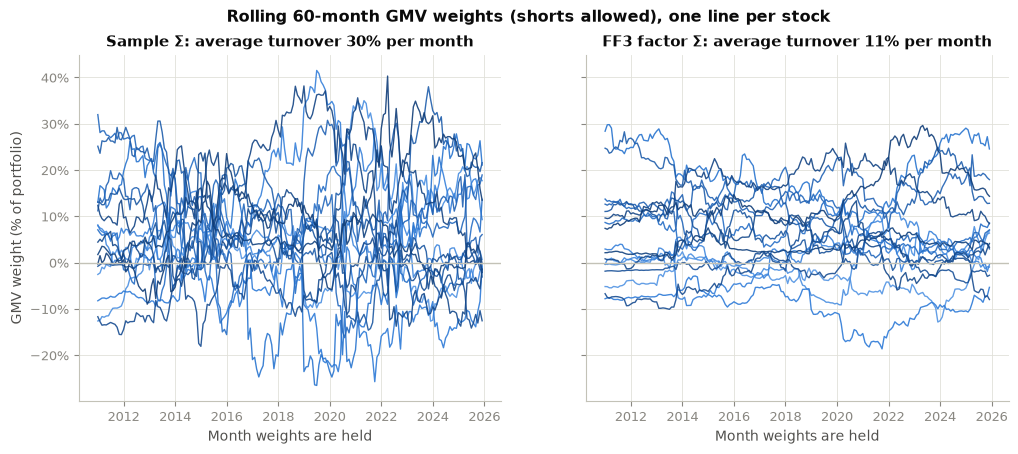

Caption: Re-estimated every month, sample-covariance GMV weights jump around; factor-model weights drift smoothly.


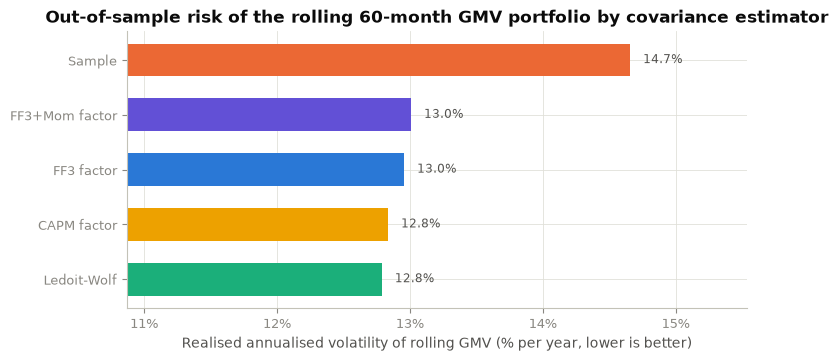

Caption: Every structured estimator delivers lower out-of-sample risk than the sample covariance when windows are short.


In [24]:
# Rolling 60-month GMV across the full period: turnover and realised risk under each estimator.
roll, paths = {}, {}
for name in covs:
    for lo in (False, True):
        W_r, r_r = bt.rolling_weights(df, T, lambda past, n=name: est.covariance_estimators(past)[n], long_only=lo)
        roll[(name, "long only" if lo else "shorts")] = {
            "avg monthly turnover": bt.turnover(W_r), "realised ann vol": r_r.std() * np.sqrt(12),
            "realised Sharpe": (r_r - df.loc[r_r.index, "RF"]).mean() / (r_r - df.loc[r_r.index, "RF"]).std() * np.sqrt(12),
        }
        if not lo and name in ("Sample", "FF3 factor"):
            paths[name] = (W_r, bt.turnover(W_r))
roll7 = save_table(pd.DataFrame(roll).T, "07_rolling_gmv")
print(f"Rolling windows: weights held {r_r.index.min()}..{r_r.index.max()} ({len(r_r)} months), 60-month estimation window")
display(roll7.style.format({"avg monthly turnover": "{:.1%}", "realised ann vol": "{:.2%}", "realised Sharpe": "{:.2f}"}))
fig = plots.rolling_weights_plot(paths)
plt.show()
caption("Re-estimated every month, sample-covariance GMV weights jump around; factor-model weights drift smoothly.")
fig = plots.gmv_vol_by_estimator(roll7.xs("shorts", level=1)["realised ann vol"])
plt.show()
caption("Every structured estimator delivers lower out-of-sample risk than the sample covariance when windows are short.")

In [25]:
save_table(fm.parameter_counts(), "07_parameter_counts")

,sample,factor K=1,factor K=3,factor K=4
N,,,,
17,153,35,74,95
20,210,41,86,110
500,125250,1001,2006,2510


**Understand this.**
- *What makes Σ = BΣ_FBᵀ + D valid?* Residuals must be uncorrelated across stocks: once the factors are removed, no
  two stocks share anything else. In our data the average FF3 residual correlation is close to zero, but specific
  pairs break it — same-sector JPM/C, and pairs like KO/JNJ (defensive "quality" stocks) that share an exposure FF3
  doesn't have a factor for.
- *Why does bias help?* The sample covariance is unbiased but estimates 153 numbers from 120 months; with 60-month
  windows it estimates 153 numbers from 60 × 17 = 1,020 noisy data points and its inverse (which GMV uses) amplifies
  the noise. The factor model estimates 17 × 3 + 6 + 17 = 74 numbers; it is slightly wrong (biased) but much less
  noisy, and the variance reduction wins — lower realised risk, far lower turnover and much tighter bootstrap weights.
- *What it bought us in our data.* With 120 months for 17 stocks, the static GMV gain is small (the sample covariance
  is already decent): long-only GMV vol falls by about half a percentage point in both orderings, shorts GMV is roughly
  unchanged. The gain shows up clearly where estimation error bites: 60-month rolling windows (turnover down by about
  two-thirds and realised vol 14.7% → 13.0%) and bootstrap weight ranges (halved). Honest caveat: the lower-risk rolling
  factor GMV also had a lower realised Sharpe (0.84 vs 0.97) over 2011–2025 — GMV targets risk, not return.
- *μ vs Σ grid.* Changing only μ or only Σ barely moves the max-Sharpe result; changing both (factor μ + factor Σ) gives
  the best max-Sharpe Sharpe in both orderings (0.73 → 0.89 forward, 0.58 → 0.77 swapped). But the best or near-best
  cell is still GMV with the sample Σ — **dropping μ altogether beats every attempt to estimate it.**

## 8. Original visualisations and experiments

Seven experiments of our own design. Our pick for the presentation is **the wobbling frontier (8.2)**: it shows in
one picture why the optimiser disappoints (max-Sharpe is all over the place) and why GMV / factor structure helps
(the GMV cloud is tight).

### 8.1 Diversification curve

**What this shows.** Volatility of an equal-weight portfolio of *n* randomly chosen stocks from our 17, averaged
over many draws, against theory σ√(ρ + (1−ρ)/n). Risk falls quickly for the first 5–8 stocks then flattens at a floor
σ√ρ: the market risk that diversification can't remove, which is exactly what beta measures.

Average stock vol 26.2%, average pairwise correlation 0.29


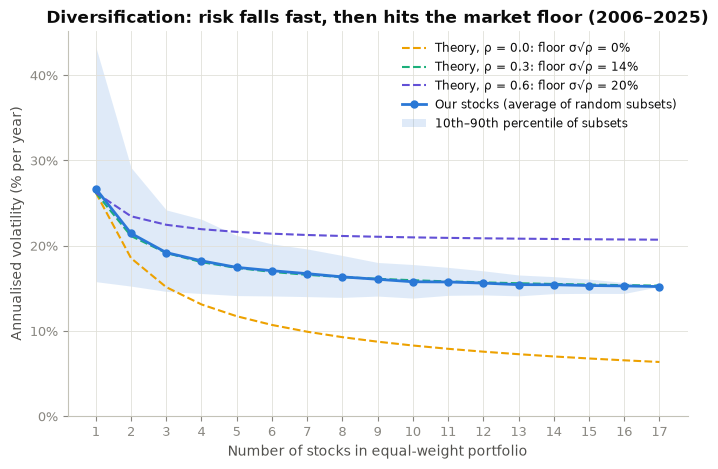

Caption: Our stocks track the theory curve for ρ ≈ 0.3: diversification removes idiosyncratic risk but not the ~14% market floor.


In [26]:
rng = np.random.default_rng(config.SEED)
R_full = df[T]
curve = {}
for n in range(1, len(T) + 1):
    vols = [R_full[rng.choice(T, n, replace=False)].mean(axis=1).std() * np.sqrt(12) for _ in range(500)]
    curve[n] = {"mean": np.mean(vols), "p10": np.percentile(vols, 10), "p90": np.percentile(vols, 90)}
curve = save_table(pd.DataFrame(curve).T, "08_diversification")
sigma_bar = (R_full.std() * np.sqrt(12)).mean()
rho_bar = R_full.corr().where(~np.eye(len(T), dtype=bool)).stack().mean()
print(f"Average stock vol {sigma_bar:.1%}, average pairwise correlation {rho_bar:.2f}")
fig = plots.diversification_curve(curve, sigma_bar, [0.0, round(rho_bar, 1), 0.6])
plt.show()
caption(f"Our stocks track the theory curve for ρ ≈ {rho_bar:.1f}: diversification removes idiosyncratic risk "
        f"but not the ~{sigma_bar * np.sqrt(rho_bar):.0%} market floor.")

### 8.2 The wobbling frontier

**What this shows.** Resample the 120 train months 50 times and redraw the long-only frontier and its GMV and
max-Sharpe points each time. The frontier — and especially the max-Sharpe point — moves a lot with nothing but sampling
noise; the GMV cloud is tight because it doesn't depend on the poorly estimated means.

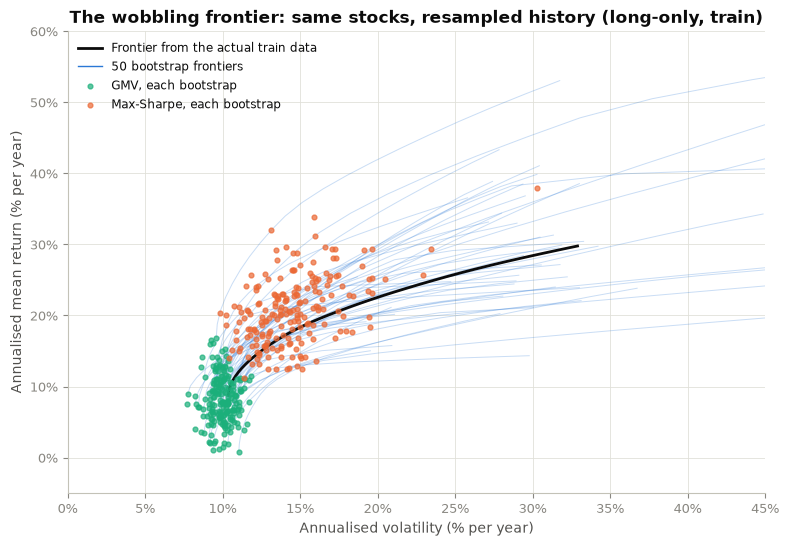

Caption: Across 200 resamples the max-Sharpe point's volatility varies 3.6x as much as GMV's (SD 2.6% vs 0.7%); the GMV cloud sits in a narrow vertical band.


In [27]:
fronts, gmv_pts, ms_pts = [], [], []
for k, sample in enumerate(est.bootstrap_months(R_train, n_boot=200, seed=config.SEED + 1)):
    m_b, S_b = sample.mean(), sample.cov()
    w_g = opt.gmv(S_b, long_only=True)
    w_m = opt.max_sharpe(m_b, S_b, rf, long_only=True)
    g, s_ = opt.portfolio_stats(w_g, m_b, S_b), opt.portfolio_stats(w_m, m_b, S_b)
    gmv_pts.append((g[0] * 12, g[1] * np.sqrt(12)))
    ms_pts.append((s_[0] * 12, s_[1] * np.sqrt(12)))
    if k < 50:
        f = opt.frontier(m_b, S_b, np.linspace(g[0], g[0] + 0.98 * (m_b.max() - g[0]), 20), long_only=True)
        fronts.append(ann(f))
gmv_pts = pd.DataFrame(gmv_pts, columns=["mean", "vol"])
ms_pts = pd.DataFrame(ms_pts, columns=["mean", "vol"])
fig = plots.wobbling_frontier(fronts, gmv_pts, ms_pts, ann(front_l))
plt.show()
wob = save_table(pd.DataFrame({"GMV": gmv_pts.std(), "Max-Sharpe": ms_pts.std()}).T, "08_wobble_sd")
caption(f"Across 200 resamples the max-Sharpe point's volatility varies {wob.loc['Max-Sharpe', 'vol'] / wob.loc['GMV', 'vol']:.1f}x as much "
        f"as GMV's (SD {wob.loc['Max-Sharpe', 'vol']:.1%} vs {wob.loc['GMV', 'vol']:.1%}); the GMV cloud sits in a narrow vertical band.")

### 8.3 Error-maximiser experiment

**What this shows.** Take the stock with the biggest max-Sharpe weight, nudge its mean up by one standard error
(a perfectly plausible estimation error) and recompute the shorts-allowed max-Sharpe weights; then instead nudge its
volatility by one standard error. The mean nudge reshuffles a large share of the portfolio; the vol nudge barely
moves it. Errors in μ dominate.

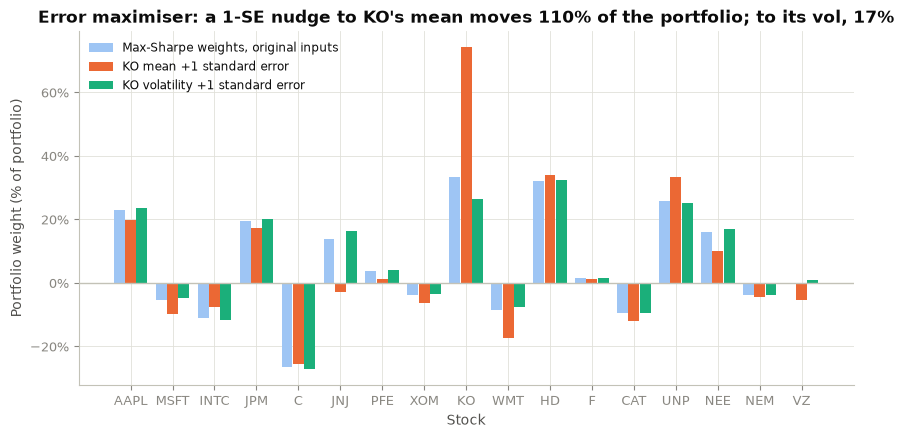

Caption: One standard error of KO's mean (4.9% a year) moves 110% of the portfolio; one SE of its vol moves 17%.


In [28]:
stock = W4["Max-Sharpe (shorts)"].idxmax()
i = T.index(stock)
base = opt.max_sharpe(mu, Sigma, rf)
se_mu = R_train[stock].std() / np.sqrt(len(R_train))
mu_b = mu.copy()
mu_b[stock] += se_mu
# SE of a standard deviation is about sigma / sqrt(2T); scale the stock's row and column to keep correlations fixed.
scale = np.ones(len(T))
scale[i] = 1 + 1 / np.sqrt(2 * len(R_train))
Sigma_b = Sigma * np.outer(scale, scale)
w_mu = opt.max_sharpe(mu_b, Sigma, rf)
w_vol = opt.max_sharpe(mu, Sigma_b, rf)
em = save_table(pd.DataFrame({"base": base, "mean +1 SE": w_mu, "vol +1 SE": w_vol}, index=T), "08_error_maximiser")
fig = plots.error_maximiser(em["base"], em["mean +1 SE"], em["vol +1 SE"], stock)
plt.show()
caption(f"One standard error of {stock}'s mean ({se_mu * 12:.1%} a year) moves "
        f"{np.abs(w_mu - base).sum():.0%} of the portfolio; one SE of its vol moves {np.abs(w_vol - base).sum():.0%}.")

### 8.4 Fund alpha decomposition

**What this shows.** Regress a real small-cap value fund (Dimensional DFSVX) and Berkshire Hathaway on CAPM, FF3 and
Carhart over 2006–2025. A fund that tilts to small and value stocks can show a CAPM "alpha" that is really just factor
exposure; once SMB and HML are in the regression, the alpha changes and the loadings tell you what the fund is.

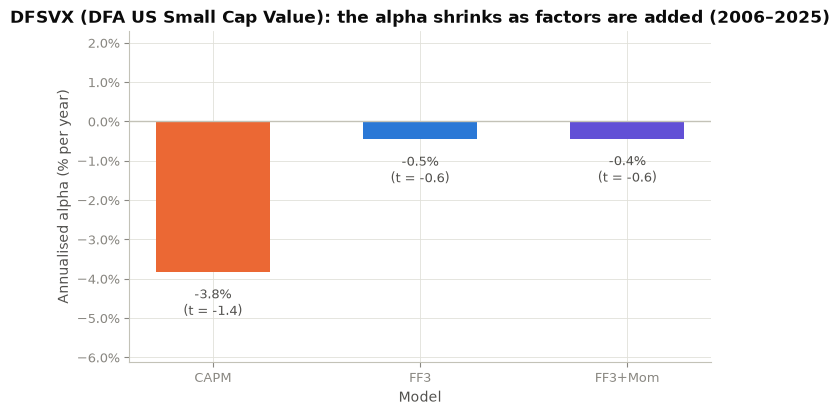

Caption: DFSVX's CAPM alpha of -3.8% becomes -0.5% under FF3: its SMB loading 0.80 and HML loading 0.63 explain its returns.


In [29]:
funds = data.load_returns(["DFSVX", "BRK-B"], config.START, config.END, "prices_funds").join(df[fm.CARHART + ["RF"]], how="inner")
fund_rows = {}
for fund in ("DFSVX", "BRK-B"):
    y = funds[fund] - funds["RF"]
    for m, cols_m in fm.MODELS.items():
        res = fm.ts_regression(y, funds[cols_m])
        row = {"alpha_ann": res.params["const"] * 12, "t_alpha": res.tvalues["const"], "r2": res.rsquared}
        row.update({f"b_{c}": res.params[c] for c in cols_m})
        fund_rows[(fund, m)] = row
fund_tab = save_table(pd.DataFrame(fund_rows).T, "08_fund_alpha")
display(fund_tab.style.format("{:.2f}").format("{:.2%}", subset=["alpha_ann"]))
dfs = fund_tab.loc["DFSVX"]
fig = plots.fund_alpha(dfs["alpha_ann"], dfs["t_alpha"], "DFSVX (DFA US Small Cap Value)")
plt.show()
caption(f"DFSVX's CAPM alpha of {dfs.loc['CAPM', 'alpha_ann']:.1%} becomes {dfs.loc['FF3', 'alpha_ann']:.1%} under FF3: "
        f"its SMB loading {dfs.loc['FF3', 'b_SMB']:.2f} and HML loading {dfs.loc['FF3', 'b_HML']:.2f} explain its returns.")

### 8.5 Factor correlation heatmap

**What this shows.** Correlations among the Fama–French 5 factors and momentum, full sample and rolling 10-year.
HML and CMA are strongly positively correlated (cheap firms tend to be conservative investors), which is why HML
looks redundant once CMA and RMW are added in FF5. HML and momentum are negatively correlated, which is why value and
momentum combine well. Factors should ideally be close to uncorrelated so each loading measures a distinct exposure
and regressions don't suffer from multicollinearity.

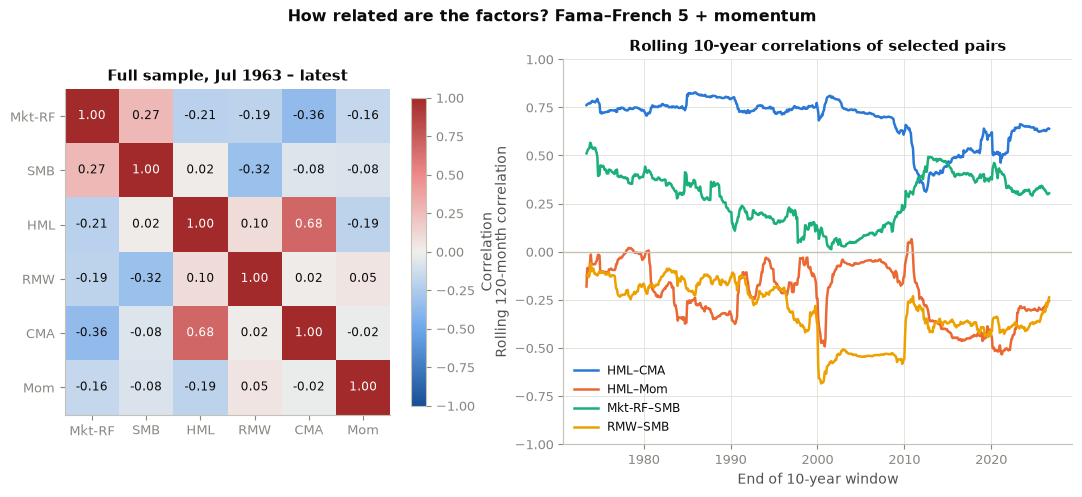

Caption: HML and CMA correlate at 0.68; HML and momentum at -0.19. Correlations drift a lot from decade to decade.


In [30]:
ff5 = data.load_french(config.FF5).join(data.load_french(config.MOM)[["Mom"]], how="inner").drop(columns="RF")
corr6 = save_table(ff5.corr(), "08_factor_corr")
roll_pairs = {"HML–CMA": ("HML", "CMA"), "HML–Mom": ("HML", "Mom"), "Mkt-RF–SMB": ("Mkt-RF", "SMB"), "RMW–SMB": ("RMW", "SMB")}
rolling = pd.DataFrame({k: ff5[a].rolling(120).corr(ff5[b]) for k, (a, b) in roll_pairs.items()}).dropna()
fig = plots.factor_correlation(corr6, rolling)
plt.show()
caption(f"HML and CMA correlate at {corr6.loc['HML', 'CMA']:.2f}; HML and momentum at {corr6.loc['HML', 'Mom']:.2f}. "
        "Correlations drift a lot from decade to decade.")

### 8.6 Survivorship experiment

**What this shows.** An equal-weight portfolio of the 10 largest US companies *as of January 2006* (GE, XOM, MSFT,
C, PG, WMT, BAC, JNJ, AIG, PFE) vs the 10 largest *today* (late 2025: NVDA, AAPL, MSFT, GOOGL, AMZN, META, AVGO,
TSLA, BRK-B, LLY), both held over 2006–2025. Names that listed after 2006 join the portfolio when they list. Choosing
stocks with today's knowledge makes any backtest look spectacular. *(Lists are approximate rankings by market cap;
the team should double-check them before quoting in the report.)*

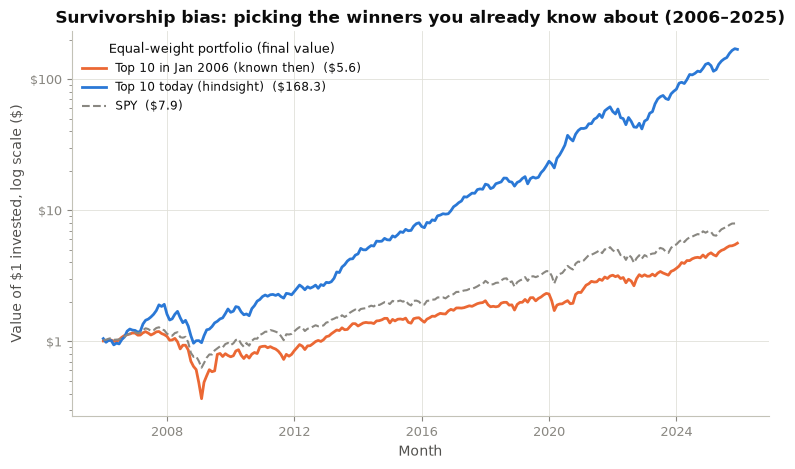

,ann_mean,ann_vol,sharpe,max_drawdown,final_wealth
Top 10 in Jan 2006 (known then),0.107,0.205,0.444,-0.692,5.608
Top 10 today (hindsight),0.280,0.207,1.277,-0.495,168.305
SPY,0.115,0.151,0.660,-0.508,7.934


Caption: Today's giants turned $1 into $168; the giants you could actually have picked in 2006 turned it into $5.6, behind SPY's $7.9.


In [31]:
top2006 = ["GE", "XOM", "MSFT", "C", "PG", "WMT", "BAC", "JNJ", "AIG", "PFE"]
top_today = ["NVDA", "AAPL", "MSFT", "GOOGL", "AMZN", "META", "AVGO", "TSLA", "BRK-B", "LLY"]
surv = data.load_returns(sorted(set(top2006 + top_today)), config.START, config.END, "prices_survivorship")
port = pd.DataFrame({
    "Top 10 in Jan 2006 (known then)": surv[top2006].mean(axis=1),
    "Top 10 today (hindsight)": surv[top_today].mean(axis=1, skipna=True),
    "SPY": df["SPY"],
})
wealth = (1 + port).cumprod()
fig = plots.survivorship(wealth)
plt.show()
surv_tab = save_table(bt.metrics(port, df["RF"]), "08_survivorship")
display(surv_tab)
caption(f"Today's giants turned $1 into ${wealth.iloc[-1, 1]:.0f}; the giants you could actually have picked in 2006 "
        f"turned it into ${wealth.iloc[-1, 0]:.1f}, behind SPY's ${wealth.iloc[-1, 2]:.1f}.")

### 8.7 A factor that moves returns without a premium: SMB

**What this shows.** Adding SMB to the market model raises the R² of small-stock portfolios a lot — SMB is an
important source of *co-movement*. But its average return has been small since Banz published the size effect in
1981. A factor can matter for risk (covariance) without being priced (no premium), which is exactly why the
covariance model in Section 7 can use factors even where their means are noisy or zero.

,ann_mean,t_stat,months
1926-07–1980-12,0.034,2.192,654
1981-01–2026-09,0.002,0.161,549


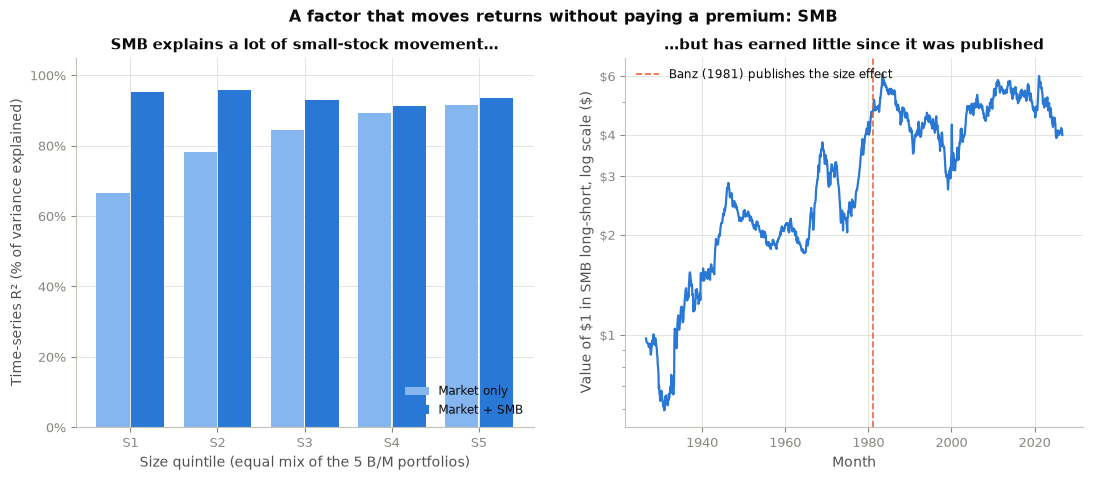

Caption: SMB raises the smallest quintile's R² from 67% to 95%, yet has averaged only 0.2% a year since 1981 (t = 0.2).


In [32]:
ff_long = data.load_french(config.FF3).loc[config.FRENCH_START:]
p25_long = p25.loc[config.FRENCH_START:].sub(ff_long["RF"], axis=0)
size_q = pd.DataFrame({f"S{i}": p25_long[[f"S{i}B{j}" for j in range(1, 6)]].mean(axis=1) for i in range(1, 6)})
r2_tab = pd.DataFrame({
    "CAPM": fm.multi_regression(size_q, ff_long[["Mkt-RF"]])["r2"],
    "Mkt + SMB": fm.multi_regression(size_q, ff_long[["Mkt-RF", "SMB"]])["r2"],
})
save_table(r2_tab, "08_smb_r2")

smb = data.load_french(config.FF3)["SMB"]
split = "1981-01"
pre, post = smb.loc[:"1980-12"], smb.loc[split:]
tstat = lambda x: x.mean() / x.std() * np.sqrt(len(x))
smb_tab = save_table(pd.DataFrame({
    "ann_mean": [pre.mean() * 12, post.mean() * 12], "t_stat": [tstat(pre), tstat(post)], "months": [len(pre), len(post)],
}, index=[f"{pre.index.min()}–1980-12", f"{split}–{post.index.max()}"]), "08_smb_pre_post")
display(smb_tab)
fig = plots.smb_no_premium(r2_tab, (1 + smb).cumprod(), split)
plt.show()
caption(f"SMB raises the smallest quintile's R² from {r2_tab.loc['S1', 'CAPM']:.0%} to {r2_tab.loc['S1', 'Mkt + SMB']:.0%}, "
        f"yet has averaged only {post.mean() * 12:.1%} a year since 1981 (t = {tstat(post):.1f}).")

## 9. Questions worth chasing

The evidence for each question, collected from the sections above.

In [33]:
ms, ew, gm = "Max-Sharpe (shorts)", "Equal weight (1/N)", "GMV (long only)"
lt = results[("1963–latest", "25 size×B/M")]
mo = results[("1963–latest", "10 momentum")]
rs = roll7.xs("shorts", level=1)
headline = pd.Series({
    "Max-Sharpe (shorts) Sharpe, predicted -> realised (fwd)": f"{tab_fwd.loc[ms, 'pred_sharpe']:.2f} -> {tab_fwd.loc[ms, 'sharpe']:.2f}",
    "Max-Sharpe (shorts) Sharpe, predicted -> realised (swap)": f"{tab_swap.loc[ms, 'pred_sharpe']:.2f} -> {tab_swap.loc[ms, 'sharpe']:.2f}",
    "1/N realised Sharpe (fwd / swap)": f"{tab_fwd.loc[ew, 'sharpe']:.2f} / {tab_swap.loc[ew, 'sharpe']:.2f}",
    "Median relative SE: mean vs vol (train)": f"{prec['rel_se_mean'].median():.0%} vs {prec['rel_se_vol'].median():.0%}",
    "CAPM cross-section slope vs CAPM line (full)": f"{fit_full['slope']:.1%} vs {mkt[labels['full']]:.1%} (R² {fit_full['r2']:.2f})",
    "Mean |alpha| on 25 portfolios, CAPM -> FF3 (1963-)": f"{lt.loc['CAPM', 'mean_abs_alpha_ann']:.2%} -> {lt.loc['FF3', 'mean_abs_alpha_ann']:.2%}",
    "Mean |alpha| on momentum, FF3 -> Carhart (1963-)": f"{mo.loc['FF3', 'mean_abs_alpha_ann']:.2%} -> {mo.loc['FF3+Mom', 'mean_abs_alpha_ann']:.2%}",
    "Rolling GMV turnover/month, sample -> FF3 Σ": f"{rs.loc['Sample', 'avg monthly turnover']:.0%} -> {rs.loc['FF3 factor', 'avg monthly turnover']:.0%}",
    "Rolling GMV realised vol, sample -> FF3 Σ": f"{rs.loc['Sample', 'realised ann vol']:.1%} -> {rs.loc['FF3 factor', 'realised ann vol']:.1%}",
    "Bootstrap GMV weight 95% range, sample -> FF3 Σ": f"{spread['Sample'].mean():.0%} -> {spread['FF3 factor'].mean():.0%}",
    "Max-Sharpe Sharpe, sample μ&Σ -> factor μ&Σ (fwd)": f"{grid[('shorts', 'fwd')].loc['Sample Σ', 'Sample μ']:.2f} -> {grid[('shorts', 'fwd')].loc['Factor Σ', 'Factor μ']:.2f}",
    "Covariance parameters N=500: sample vs FF3": f"{fm.parameter_counts().loc[500, 'sample']:,} vs {fm.parameter_counts().loc[500, 'factor K=3']:,}",
}, name="value")
save_table(headline.to_frame(), "09_headline_numbers")

,value
"Max-Sharpe (shorts) Sharpe, predicted -> realised (fwd)",1.55 -> 0.73
"Max-Sharpe (shorts) Sharpe, predicted -> realised (swap)",2.02 -> 0.58
1/N realised Sharpe (fwd / swap),0.98 / 0.64
Median relative SE: mean vs vol (train),65% vs 7%
CAPM cross-section slope vs CAPM line (full),2.8% vs 10.2% (R² 0.05)
"Mean |alpha| on 25 portfolios, CAPM -> FF3 (1963-)",2.32% -> 1.04%
"Mean |alpha| on momentum, FF3 -> Carhart (1963-)",3.30% -> 1.45%
"Rolling GMV turnover/month, sample -> FF3 Σ",30% -> 11%
"Rolling GMV realised vol, sample -> FF3 Σ",14.7% -> 13.0%
"Bootstrap GMV weight 95% range, sample -> FF3 Σ",23% -> 12%


- **Why does the optimal portfolio lose to 1/N, and is it μ or Σ?** Sections 4, 7 and 8.3. The max-Sharpe portfolio's
  promised Sharpe roughly halves out of sample in both orderings. Mainly μ: a one-SE error in a single mean moves 110% of
  the portfolio while a one-SE error in a vol moves 17% (8.3), and GMV — which uses no μ — matches or beats every
  max-Sharpe variant in the grid. Σ matters second: structuring Σ helps most when data are short (rolling windows)
  and only in combination with a structured μ for max-Sharpe.
- **How many numbers for 20 vs 500 stocks?** Section 7 table: 210 vs 86 (N = 20, K = 3) and 125,250 vs 2,006
  (N = 500). With 500 stocks and 20 years of monthly data (240 months) the sample covariance isn't even invertible.
- **Should max-Sharpe look like the index?** Under the CAPM, yes. Ours is concentrated, has large shorts and is only
  loosely correlated with SPY — not because the CAPM fails, but because our μ estimates are noise.
- **Risk, mispricing or luck?** Section 6 and 8.7: size had a strong premium before 1981 and little after
  publication, which looks like luck or mispricing that got arbitraged. Value and momentum premia are more persistent.
- **Factor that moves returns without a premium:** SMB (8.7).
- **Sensitivity to period/stocks:** swapping halves (Section 4) preserves every qualitative conclusion; the
  survivorship experiment (8.6) shows the choice of stocks can matter more than any optimiser.

## 10. Figures written

Every figure in this notebook is saved to `figures/` at 200 dpi; every table quoted in the report is saved to
`report/tables/`.

In [34]:
print("\n".join(sorted(p.name for p in config.FIGURES_DIR.glob("*.png"))))

01_mean_ci.png
02_frontier.png
03_oos_wealth.png
03b_oos_wealth_swapped.png
04_pred_vs_real.png
04b_pred_vs_real_swapped.png
05_beta_vs_return.png
06_actual_vs_predicted.png
06b_actual_vs_predicted.png
07_alpha_heatmap.png
07b_alpha_heatmap.png
08_weight_stability.png
09_rolling_gmv_weights.png
10_gmv_vol_by_estimator.png
11_diversification.png
12_wobbling_frontier.png
13_error_maximiser.png
14_fund_alpha.png
15_factor_correlation.png
16_survivorship.png
17_smb_movement_no_premium.png
